# Comparación visual de K-Means — clientes Samsung en T1 (solo TRAIN)

Compara B con K=3, B con K=4 y C con K=3 con evidencias del análisis real.
B-K4 está seleccionado por su Silhouette, cuatro perfiles comerciales y estabilidad,
NO porque gane todas las métricas. El codo de B aparece alrededor de K=3.

**Antes de ejecutar:** asegúrate de que los CSV originales están en el proyecto.
El código busca archivos en la raíz y en las carpetas usadas en los notebooks anteriores.
Si hace falta, asigna `RUTA_BASE_MANUAL` a la carpeta raíz del proyecto.

No usa TEST, no reajusta K-Means y no modifica los archivos fuente.

In [1]:
from pathlib import Path
from config_matrices import MIN_MONETARY_T1, TAG, CARPETA_SALIDA, ruta_matrices, cargar_W_train
from zipfile import ZipFile, ZIP_DEFLATED
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

RUTA_BASE_MANUAL = None  # Ejemplo en Windows: Path(r"C:\Users\usuario\Documents\Tesis")
NOMBRE_SALIDA = f"graficos_comparacion_KMeans_T1{TAG}"

if RUTA_BASE_MANUAL is not None:
    BASES = [Path(RUTA_BASE_MANUAL).expanduser().resolve()]
else:
    BASES = [Path.cwd().resolve(), Path.cwd().resolve().parent, Path("/mnt/data")]

BUSQUEDA = [
    "", f"resultados_segmentacion_T1_train{TAG}",
    f"resultados_kmeans_python{TAG}",
]

def localizar(nombre):
    intentos = []
    for base in BASES:
        for carpeta in BUSQUEDA:
            p = base / carpeta / nombre
            intentos.append(str(p))
            if p.is_file():
                return p
    raise FileNotFoundError(
        f"No se encontró {nombre}. Configura RUTA_BASE_MANUAL.\n"
        + "\n".join(intentos)
    )

paths = {
    "exploracion": localizar("exploracion_A_B_C_k2_k10.csv"),
    "metricas": localizar("tabla_integrada_evidencia_candidatos.csv"),
    "estabilidad": localizar("estabilidad_resumen_por_fraccion_y_repeticiones.csv"),
    "sensibilidad": localizar("sensibilidad_kmeans_K_seleccionados.csv"),
    "perfiles": localizar("perfiles_train_seis_candidatos.csv"),
    "cruce": localizar("cruce_B_RFM_ratio_4_K3_vs_B_RFM_ratio_4_K4_conteos.csv"),
}

exploracion = pd.read_csv(paths["exploracion"])
metricas = pd.read_csv(paths["metricas"])
estabilidad = pd.read_csv(paths["estabilidad"])
sensibilidad = pd.read_csv(paths["sensibilidad"])
perfiles = pd.read_csv(paths["perfiles"])
cruce = pd.read_csv(paths["cruce"], index_col=0)

# No sumar ni comparar directamente WSS de B y C: tienen dimensiones distintas.
CANDIDATOS = [
    ("B_RFM_ratio_4", 3, "B · K=3"),
    ("B_RFM_ratio_4", 4, "B · K=4"),
    ("C_W_6", 3, "C · K=3"),
]
ETIQUETAS = [c[2] for c in CANDIDATOS]
PALETA = {"B · K=3": "#6E8BA4", "B · K=4": "#0F766E", "C · K=3": "#B88C5B"}
VERDE = PALETA["B · K=4"]
AMBAR = PALETA["C · K=3"]
GRIS = "#606B75"

filas = []
for configuracion, k, nombre in CANDIDATOS:
    f = metricas.loc[(metricas.configuracion == configuracion) & (metricas.k == k)]
    if len(f) != 1:
        raise ValueError(f"Se esperaba una fila para {configuracion}, K={k}; encontradas: {len(f)}")
    filas.append({**f.iloc[0].to_dict(), "modelo": nombre})
comparacion = pd.DataFrame(filas).set_index("modelo").loc[ETIQUETAS]
# El consolidado no reporta el ARI-log1p para C-K3; está en el CSV de sensibilidad.
# Recuperarlo directamente sin imputar ni inventar el dato.
c_log = sensibilidad[(sensibilidad.familia == "C") & (sensibilidad.k == 3) &
                    (sensibilidad.escenario == "C_log1p_gastos")]
if len(c_log) != 1:
    raise ValueError("Falta el resultado de sensibilidad C-K3 para log1p")
comparacion.loc["C · K=3", "ARI_log1p_vs_original"] = float(c_log.ARI_vs_referencia.iloc[0])

# Validación de perfiles y reproducibilidad de números
# N de TRAIN según el TAG (cambia con MIN_MONETARY_T1); se toma de los propios perfiles.
N_TRAIN = int(perfiles[(perfiles.configuracion == CANDIDATOS[0][0]) & (perfiles.k == CANDIDATOS[0][1])].n_clientes.sum())
for conf,k,nombre in CANDIDATOS:
    grupos = perfiles[(perfiles.configuracion==conf)&(perfiles.k==k)]
    assert len(grupos)==k, f"Faltan grupos de {nombre}"
    assert grupos.n_clientes.sum()==N_TRAIN, f"El número de clientes de {nombre} no coincide con {N_TRAIN}"

# En .py, exportar junto al script; en Jupyter, usar la carpeta activa del proyecto.
BASE_SALIDA = (Path(RUTA_BASE_MANUAL).expanduser().resolve() if RUTA_BASE_MANUAL
               else (Path(__file__).resolve().parent if "__file__" in globals()
                     else Path.cwd().resolve()))
SALIDAS = BASE_SALIDA / NOMBRE_SALIDA
SALIDAS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 115,
    "savefig.dpi": 200,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
ARCHIVOS_GRAFICOS = []

def guardar(fig, nombre):
    destino = SALIDAS / nombre
    fig.savefig(destino, dpi=200, bbox_inches="tight", facecolor="white")
    ARCHIVOS_GRAFICOS.append(destino)
    plt.show()
    plt.close(fig)
    print("Guardado:", destino.name)

print("MIN_MONETARY_T1:", MIN_MONETARY_T1, "| TAG:", TAG, "| N TRAIN:", N_TRAIN)
print("Archivos encontrados:")
for clave,ruta in paths.items(): print(f" - {clave}: {ruta}")
print("\nResumen estadístico:")
display(comparacion[["silhouette_train", "davies_bouldin_train", "calinski_harabasz_train", "ARI_media", "min_cluster_pct", "ARI_log1p_vs_original"]].round(4)) if "display" in globals() else print(comparacion[["silhouette_train", "davies_bouldin_train", "calinski_harabasz_train", "ARI_media", "min_cluster_pct", "ARI_log1p_vs_original"]].round(4).to_string())

FileNotFoundError: No se encontró tabla_integrada_evidencia_candidatos.csv. Configura RUTA_BASE_MANUAL.
C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\tabla_integrada_evidencia_candidatos.csv
C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_segmentacion_T1_train_min80\tabla_integrada_evidencia_candidatos.csv
C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_kmeans_python_min80\tabla_integrada_evidencia_candidatos.csv
C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\tabla_integrada_evidencia_candidatos.csv
C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\resultados_segmentacion_T1_train_min80\tabla_integrada_evidencia_candidatos.csv
C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\resultados_kmeans_python_min80\tabla_integrada_evidencia_candidatos.csv
\mnt\data\tabla_integrada_evidencia_candidatos.csv
\mnt\data\resultados_segmentacion

## Figura 1: codo y Silhouette dentro de B

El codo geométrico indica K=3. K=4 obtiene una Silhouette superior y una reducción
de la WSS adicional, pero WSS desciende necesariamente al incrementar K.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


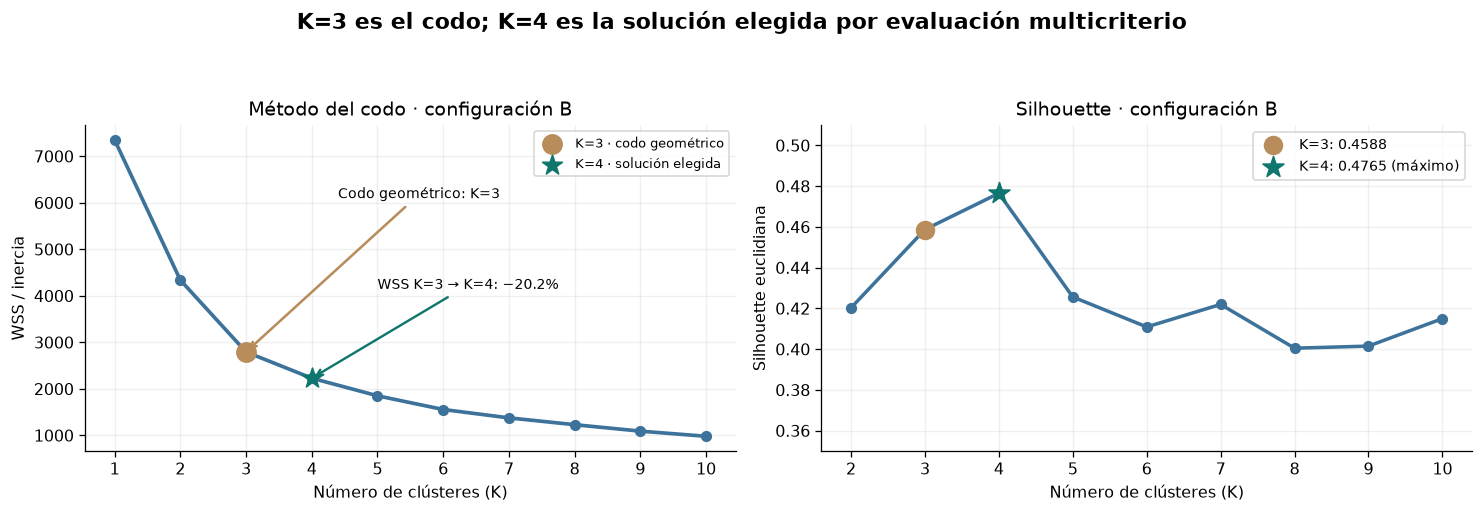

Guardado: 01_codo_vs_silhouette_B.png


In [ ]:
b = exploracion[exploracion.configuracion == "B_RFM_ratio_4"].sort_values("k")
kvals = np.r_[1, b.k.to_numpy(dtype=int)]
# Para Z-score muestral de TRAIN: suma de cuadrados en K=1 = (n-1)*p.
wss_k1 = (N_TRAIN-1) * 4
wss = np.r_[wss_k1, b.inercia.to_numpy()]
sil = b.silhouette_euclidean.to_numpy()
w3 = float(b.loc[b.k == 3,"inercia"].iloc[0])
w4 = float(b.loc[b.k == 4,"inercia"].iloc[0])
s3 = float(b.loc[b.k == 3,"silhouette_euclidean"].iloc[0])
s4 = float(b.loc[b.k == 4,"silhouette_euclidean"].iloc[0])

fig, axes = plt.subplots(1,2,figsize=(13,4.6))
ax = axes[0]
ax.plot(kvals, wss, marker="o", lw=2.3, c="#3D729B", markersize=6)
ax.scatter([3],[w3], color=AMBAR,s=145,zorder=5,label="K=3 · codo geométrico")
ax.scatter([4],[w4], color=VERDE,s=170,marker="*",zorder=6,label="K=4 · solución elegida")
ax.annotate("Codo geométrico: K=3",xy=(3,w3),xytext=(4.4,6100),
            arrowprops={"arrowstyle":"->","color":AMBAR,"lw":1.6},fontsize=9)
ax.annotate(f"WSS K=3 → K=4: −{(w3-w4)/w3*100:.1f}%",xy=(4,w4),xytext=(5.0,4150),
            arrowprops={"arrowstyle":"->","color":VERDE,"lw":1.5},fontsize=9)
ax.set(xlabel="Número de clústeres (K)", ylabel="WSS / inercia", title="Método del codo · configuración B")
ax.set_xticks(range(1,11)); ax.grid(alpha=.2); ax.legend(loc="upper right",fontsize=8)

ax=axes[1]
ax.plot(b.k,sil,marker="o",lw=2.2,c="#3D729B")
ax.scatter([3],[s3],color=AMBAR,s=125,zorder=5,label=f"K=3: {s3:.4f}")
ax.scatter([4],[s4],color=VERDE,marker="*",s=190,zorder=6,label=f"K=4: {s4:.4f} (máximo)")
ax.set(xlabel="Número de clústeres (K)",ylabel="Silhouette euclidiana",title="Silhouette · configuración B")
ax.set_xticks(range(2,11));ax.set_ylim(.35,.51);ax.grid(alpha=.2);ax.legend(fontsize=9)
fig.suptitle("K=3 es el codo; K=4 es la solución elegida por evaluación multicriterio",weight="semibold",fontsize=14)
fig.tight_layout(rect=[0,.02,1,.92])
guardar(fig,"01_codo_vs_silhouette_B.png")

## Figura 2: comparación de calidad interna

El gráfico deja visible que B-K4 gana en Silhouette, pero C-K3 gana en
Davies-Bouldin y Calinski-Harabasz. Así se evita seleccionar evidencia a favor.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


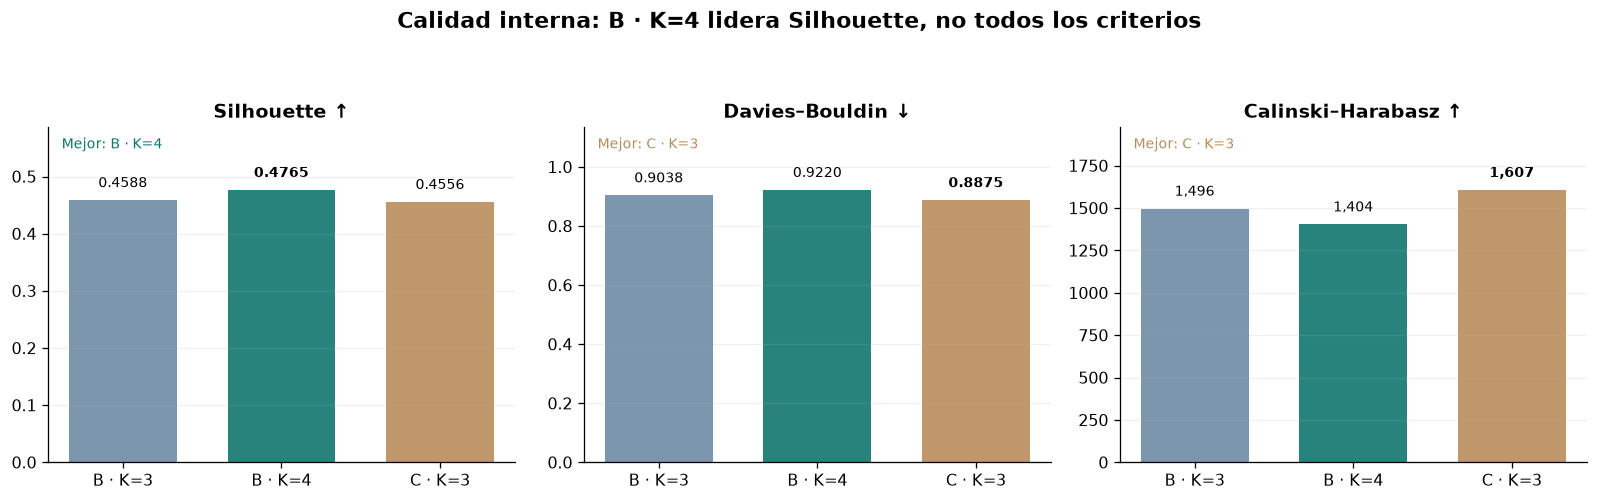

Guardado: 02_calidad_interna_tres_modelos.png


In [ ]:
fig, axes=plt.subplots(1,3,figsize=(14,4.4))
indicadores=[
    ("silhouette_train","Silhouette ↑","Mayor es mejor","max"),
    ("davies_bouldin_train","Davies–Bouldin ↓","Menor es mejor","min"),
    ("calinski_harabasz_train","Calinski–Harabasz ↑","Mayor es mejor","max"),
]
for ax,(col,titulo,descripcion,orden) in zip(axes,indicadores):
    vals=comparacion[col]
    best=vals.idxmax() if orden=="max" else vals.idxmin()
    ax.bar(ETIQUETAS,vals.values,color=[PALETA[m] for m in ETIQUETAS],alpha=.90,width=.68)
    ax.set_title(titulo,weight="semibold")
    ax.set_ylim(0,max(vals)*1.23)
    ax.tick_params(axis="x",rotation=0)
    ax.grid(axis="y",alpha=.18)
    for i,(m,v) in enumerate(zip(ETIQUETAS, vals)):
        ax.text(i,v+max(vals)*.035,f"{v:.4f}" if col!="calinski_harabasz_train" else f"{v:,.0f}",
                ha="center",va="bottom",fontsize=9,weight="bold" if m==best else "normal")
    ax.text(.03,.97,f"Mejor: {best}",ha="left",va="top",transform=ax.transAxes,
            fontsize=8.5,color=PALETA[best])
fig.suptitle("Calidad interna: B · K=4 lidera Silhouette, no todos los criterios",fontsize=14,weight="semibold")
fig.tight_layout(rect=[0,0,1,.91])
guardar(fig,"02_calidad_interna_tres_modelos.png")

## Figura 3: estabilidad al cambiar tamaño de submuestra

Se grafican resultados de **300 repeticiones** por proporción. C-K3 es ligeramente
más estable: no es correcto etiquetar B-K4 como ganador en estabilidad.

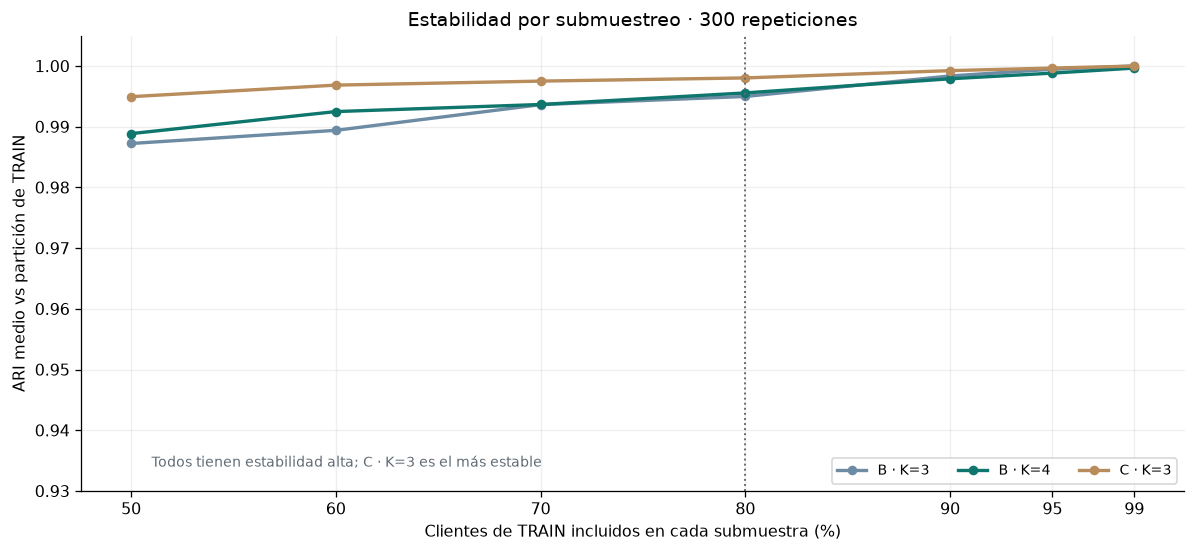

Guardado: 03_estabilidad_ARI_por_fraccion.png


In [ ]:
fig, ax=plt.subplots(figsize=(10.5,4.9))
for conf,k,nombre in CANDIDATOS:
    x=estabilidad[(estabilidad.configuracion==conf)&(estabilidad.k==k)&
                  (estabilidad.n_repeticiones==300)].sort_values("porcentaje_submuestra")
    ax.plot(x.porcentaje_submuestra,x.ARI_media,marker="o",lw=2.1,markersize=5,
            c=PALETA[nombre],label=nombre)
ax.axvline(80,color=GRIS,ls=":",lw=1.2)
ax.set(xlabel="Clientes de TRAIN incluidos en cada submuestra (%)",
       ylabel="ARI medio vs partición de TRAIN",
       title="Estabilidad por submuestreo · 300 repeticiones")
ax.grid(alpha=.20);ax.set_ylim(.93,1.005)
ax.set_xticks([50,60,70,80,90,95,99]);ax.legend(loc="lower right",ncol=3,fontsize=9)
ax.text(51,.934,"Todos tienen estabilidad alta; C · K=3 es el más estable",fontsize=9,color=GRIS)
fig.tight_layout()
guardar(fig,"03_estabilidad_ARI_por_fraccion.png")

## Figura 4: sensibilidad a cambios de preprocesamiento

ARI=1 significa las mismas asignaciones (salvo permutación de etiquetas).
B-K4 es menos resistente a log1p que B-K3; esta limitación debe declararse.

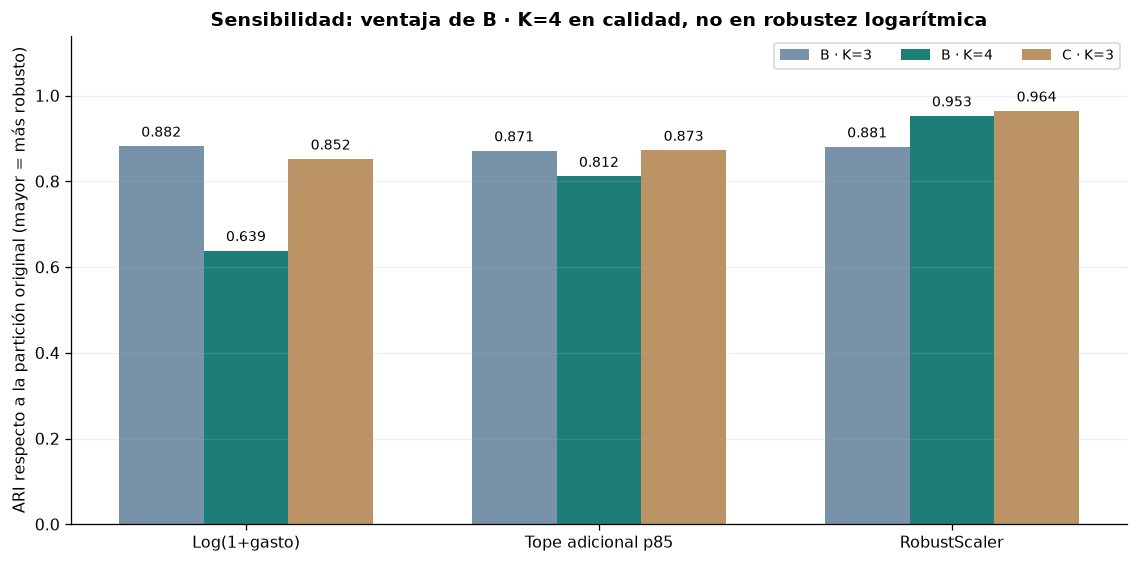

Guardado: 04_sensibilidad_transformaciones.png


In [ ]:
mapa_escenarios={
    "B · K=3": {"Log(1+gasto)":"B_log1p_gasto", "Tope adicional p85":"B_tope_extra_p85", "RobustScaler":"B_escalado_robusto"},
    "B · K=4": {"Log(1+gasto)":"B_log1p_gasto", "Tope adicional p85":"B_tope_extra_p85", "RobustScaler":"B_escalado_robusto"},
    "C · K=3": {"Log(1+gasto)":"C_log1p_gastos", "Tope adicional p85":"C_tope_extra_p85", "RobustScaler":"C_escalado_robusto"},
}
frases=["Log(1+gasto)","Tope adicional p85","RobustScaler"]
fig,ax=plt.subplots(figsize=(10,5.0))
X=np.arange(3);w=.24
for j,(conf,k,nombre) in enumerate(CANDIDATOS):
    arr=[]
    for escenario in frases:
        r=sensibilidad[(sensibilidad.familia==conf[0])&(sensibilidad.k==k)&
                       (sensibilidad.escenario==mapa_escenarios[nombre][escenario])]
        if len(r)!=1:raise ValueError(f"No se encontró escenario {nombre}, {escenario}")
        arr.append(float(r.ARI_vs_referencia.iloc[0]))
    coords=X+(j-1)*w
    bars=ax.bar(coords,arr,width=w,label=nombre,color=PALETA[nombre],alpha=.94)
    for bar,v in zip(bars,arr):
        ax.text(bar.get_x()+bar.get_width()/2,v+.022,f"{v:.3f}",ha="center",fontsize=8.5)
ax.set_xticks(X,frases);ax.set_ylim(0,1.14);ax.grid(axis="y",alpha=.2)
ax.set_ylabel("ARI respecto a la partición original (mayor = más robusto)")
ax.set_title("Sensibilidad: ventaja de B · K=4 en calidad, no en robustez logarítmica",weight="semibold")
ax.legend(ncol=3,loc="upper right",fontsize=9)
fig.tight_layout()
guardar(fig,"04_sensibilidad_transformaciones.png")

## Figura 5: tamaños y porcentajes de los grupos

Comprobar tamaño es una condición de plausibilidad comercial, no una prueba
de optimalidad. Se presentan datos reales de cada solución en TRAIN.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


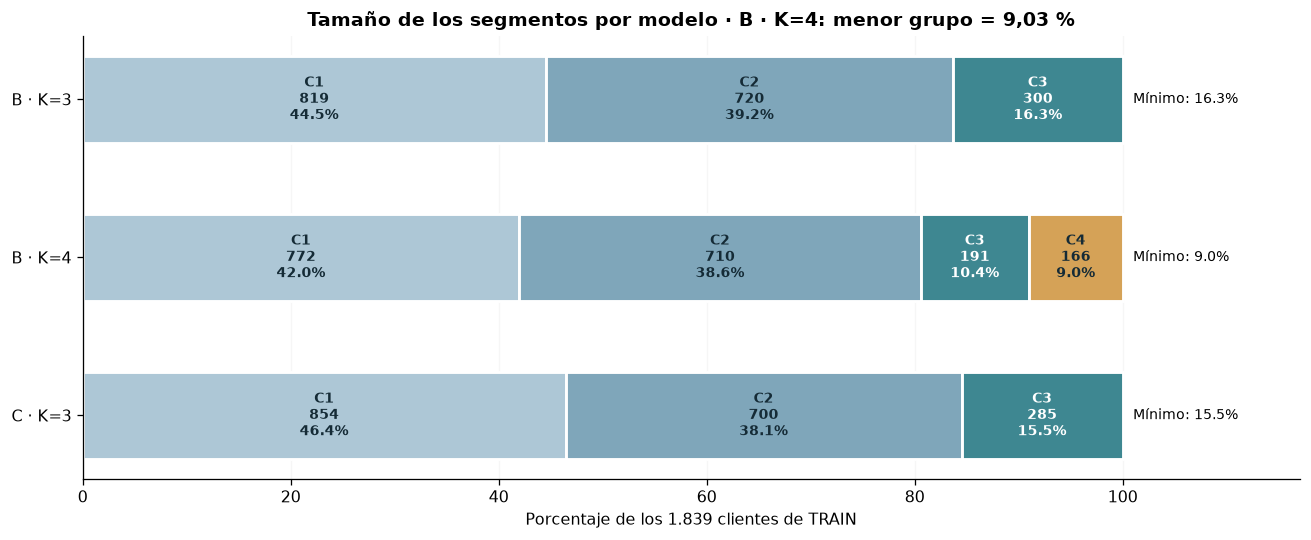

Guardado: 05_tamanos_clusters_tres_modelos.png


In [ ]:
fig,ax=plt.subplots(figsize=(11.5,4.8))
colores_segmentos=["#ADC7D6","#7FA6BA","#3E8791","#D5A257"]
for pos,(conf,k,nombre) in enumerate(CANDIDATOS):
    t=perfiles[(perfiles.configuracion==conf)&(perfiles.k==k)].sort_values("cluster")
    acumulado=0
    for _,fila in t.iterrows():
        valor=float(fila.pct_clientes)
        ax.barh(pos,valor,left=acumulado,height=.55,color=colores_segmentos[int(fila.cluster)-1],edgecolor="white",lw=1.8)
        ax.text(acumulado+valor/2,pos,f"C{int(fila.cluster)}\n{int(fila.n_clientes)}\n{valor:.1f}%",
                ha="center",va="center",fontsize=8.5,
                color="white" if int(fila.cluster)==3 else "#152B36",weight="semibold")
        acumulado+=valor
    ax.text(101,pos,f"Mínimo: {t.pct_clientes.min():.1f}%",va="center",fontsize=9)
ax.set_yticks(range(3),ETIQUETAS);ax.set_xlim(0,117);ax.invert_yaxis()
ax.set_xlabel(f"Porcentaje de los {N_TRAIN} clientes de TRAIN")
ax.set_title("Tamaño de los segmentos por modelo · B · K=4: menor grupo = 9,03 %",weight="semibold")
ax.grid(axis="x",alpha=.1);ax.set_axisbelow(True)
fig.tight_layout()
guardar(fig,"05_tamanos_clusters_tres_modelos.png")

## Figura 6: perfiles transaccionales en B-K4

Se muestran medianas en la escala de T1 (las variables ya vienen winsorizadas
en el CSV de entrada) y proporciones de actividad reciente.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


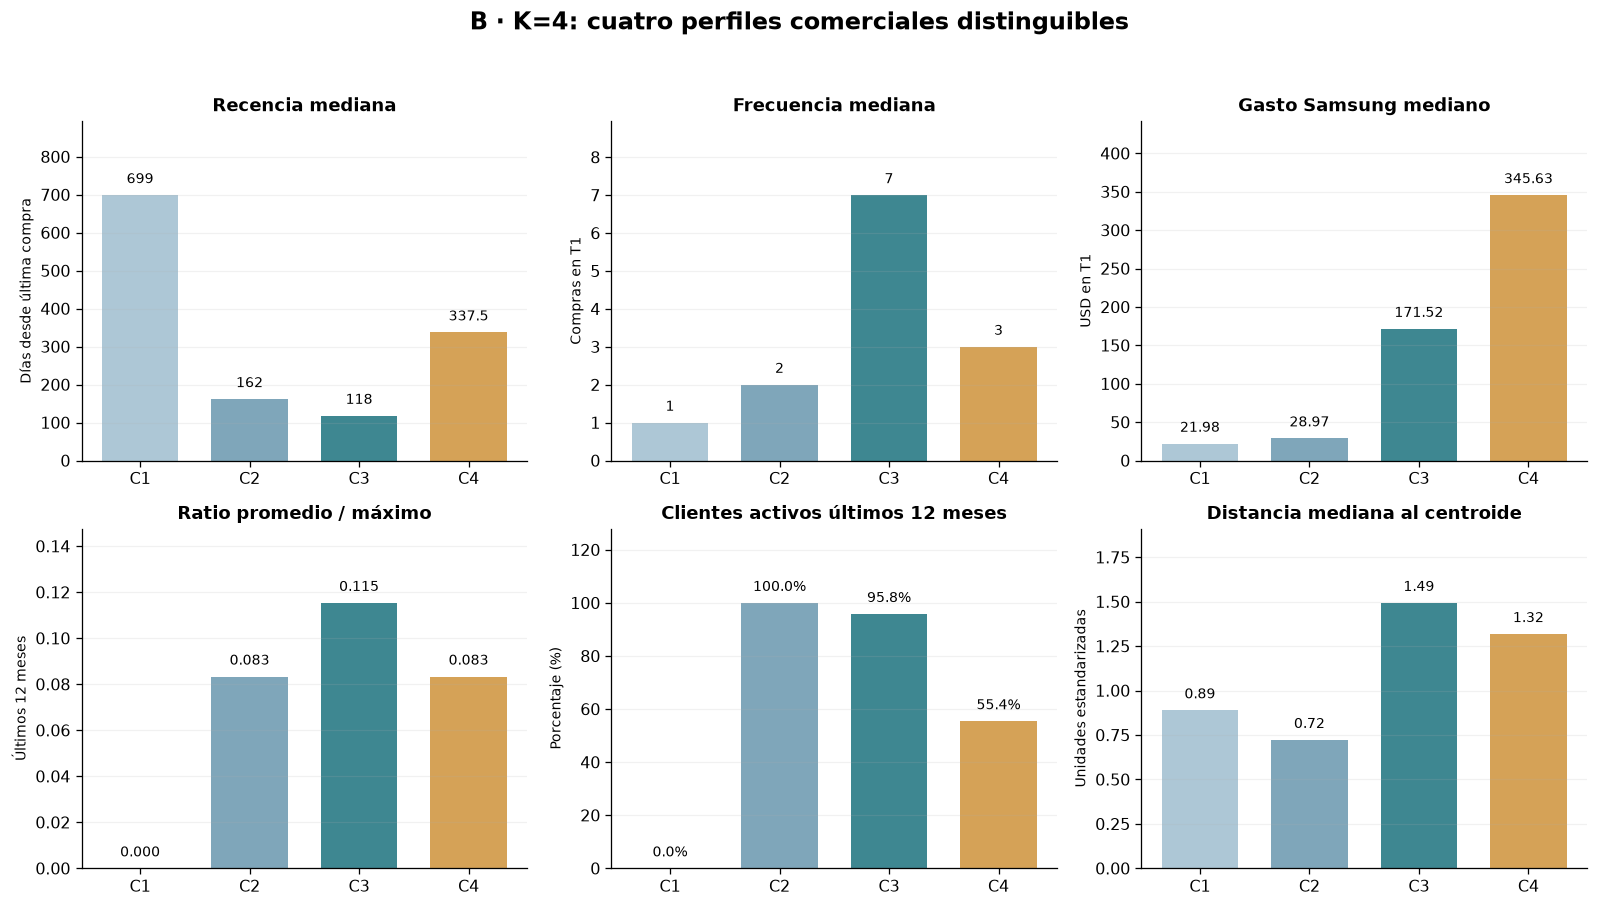

Guardado: 06_perfiles_comerciales_B_K4.png


In [ ]:
t=perfiles[(perfiles.configuracion=="B_RFM_ratio_4")&(perfiles.k==4)].sort_values("cluster")
labels=[f"C{int(c)}" for c in t.cluster]
cols=["#ADC7D6","#7FA6BA","#3E8791","#D5A257"]
indicadores_perfiles=[
    ("recency_days_2018_Samsung_mediana","Recencia mediana","Días desde última compra"),
    ("frequency_2018_Samsung_mediana","Frecuencia mediana","Compras en T1"),
    ("monetary_2018_Samsung_mediana","Gasto Samsung mediano","USD en T1"),
    ("dollar_avg12_top1_ratio_mediana","Ratio promedio / máximo","Últimos 12 meses"),
    ("pct_activos_12m","Clientes activos últimos 12 meses","Porcentaje (%)"),
    ("mediana_distancia_centroide_z","Distancia mediana al centroide","Unidades estandarizadas")
]
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,(campo,titulo,unidad) in zip(axes.ravel(),indicadores_perfiles):
    valores=t[campo].to_numpy()
    ax.bar(labels,valores,color=cols,width=.70)
    ax.set_title(titulo,weight="semibold",fontsize=11)
    ax.set_ylabel(unidad,fontsize=9)
    ax.grid(axis="y",alpha=.17)
    ax.set_ylim(0,max(valores)*1.28 if max(valores)>0 else 1)
    for j,v in enumerate(valores):
        if campo=="dollar_avg12_top1_ratio_mediana":txt=f"{v:.3f}"
        elif campo=="mediana_distancia_centroide_z":txt=f"{v:.2f}"
        elif campo=="pct_activos_12m":txt=f"{v:.1f}%"
        elif campo=="monetary_2018_Samsung_mediana":txt=f"{v:.2f}"
        else:txt=f"{v:g}"
        ax.text(j,v+max(valores)*.045,txt,ha="center",fontsize=9)
fig.suptitle("B · K=4: cuatro perfiles comerciales distinguibles",fontsize=15,weight="semibold")
fig.tight_layout(rect=[0,0,1,.95])
guardar(fig,"06_perfiles_comerciales_B_K4.png")

## Figura 7: qué cambia de B-K3 a B-K4

La cuarta partición incorpora clientes de los tres grupos previos; no es
solamente una escisión pura del anterior segmento de compradores de mayor gasto.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


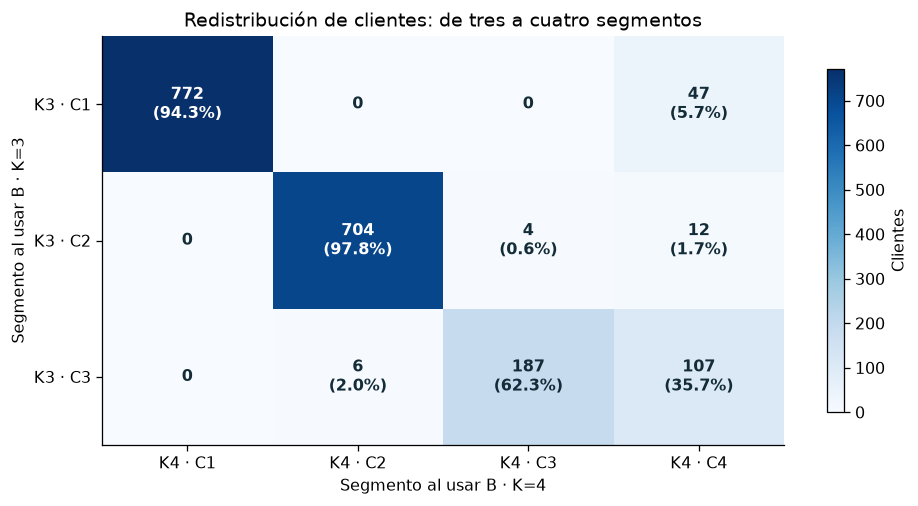

Guardado: 07_cruce_B_K3_vs_B_K4.png


In [ ]:
cruce.index=cruce.index.astype(str)
cruce.columns=cruce.columns.astype(str)
mat=cruce.to_numpy(dtype=int)
fig,ax=plt.subplots(figsize=(8.5,4.5))
im=ax.imshow(mat,cmap="Blues",aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        n=mat[i,j]
        if n==0:txt="0"
        else:txt=f"{n}\n({100*n/mat[i].sum():.1f}%)"
        ax.text(j,i,txt,ha="center",va="center",fontsize=10,
                color="white" if n>np.max(mat)*.54 else "#132C37",weight="semibold")
ax.set_xticks(np.arange(mat.shape[1]),[f"K4 · C{j}" for j in cruce.columns])
ax.set_yticks(np.arange(mat.shape[0]),[f"K3 · C{i}" for i in cruce.index])
ax.set(xlabel="Segmento al usar B · K=4",ylabel="Segmento al usar B · K=3",
       title="Redistribución de clientes: de tres a cuatro segmentos")
fig.colorbar(im,ax=ax,label="Clientes",shrink=.84)
fig.tight_layout()
guardar(fig,"07_cruce_B_K3_vs_B_K4.png")

## Figura 8: lámina ejecutiva con la comparación de tres candidatos

Una vista para exposición: calidad, estabilidad y tamaño, dejando visible
la vulnerabilidad de B-K4 a log1p. No representa una puntuación compuesta.

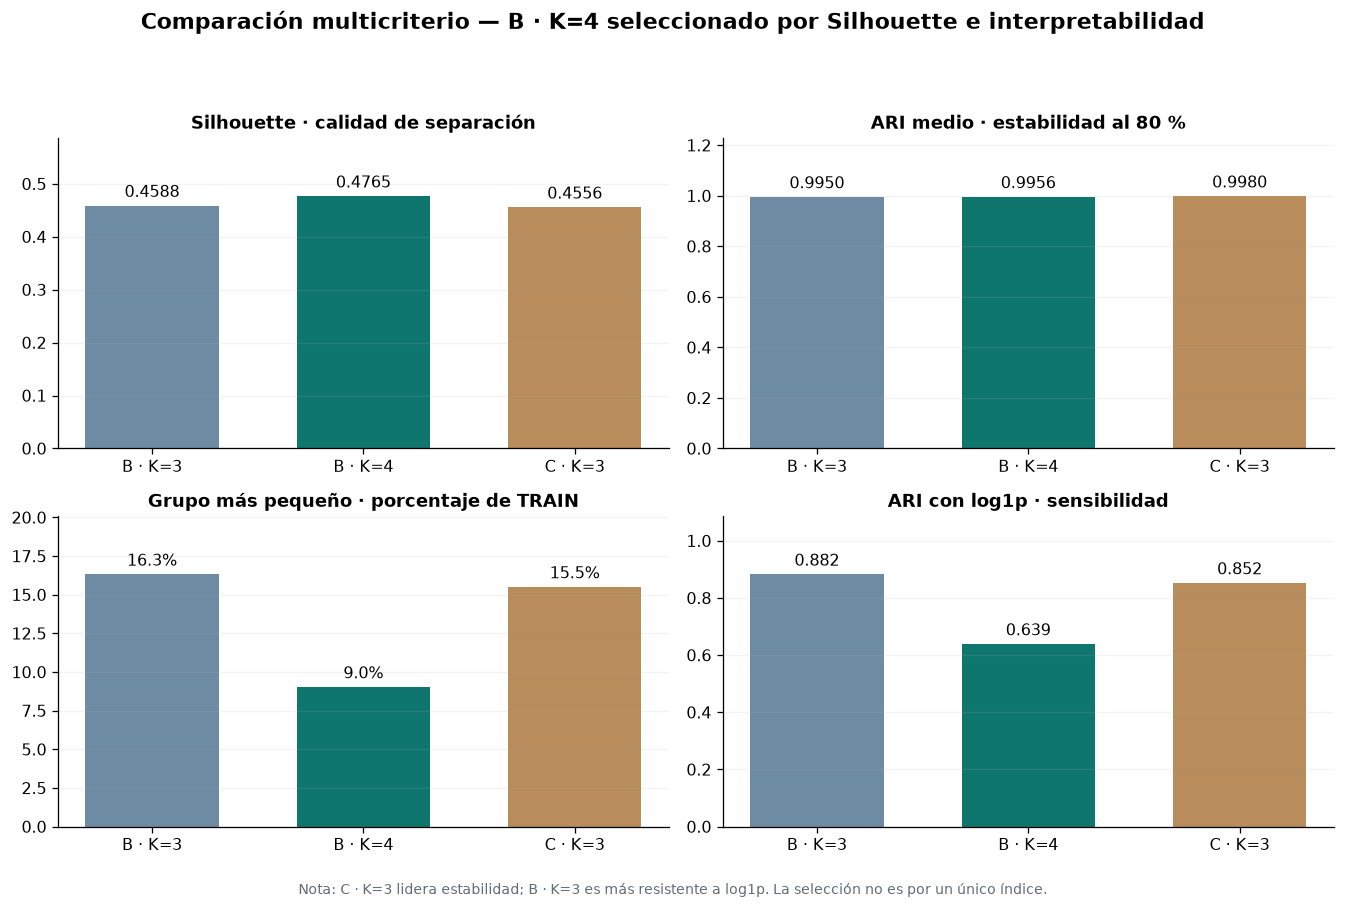

Guardado: 08_resumen_visual_para_tesis.png


In [ ]:
fig,axes=plt.subplots(2,2,figsize=(11.8,8))
resumen=[
    ("silhouette_train","Silhouette · calidad de separación", "max","{:.4f}"),
    ("ARI_media","ARI medio · estabilidad al 80 %", "max","{:.4f}"),
    ("min_cluster_pct","Grupo más pequeño · porcentaje de TRAIN", "max","{:.1f}%"),
    ("ARI_log1p_vs_original","ARI con log1p · sensibilidad", "max","{:.3f}"),
]
for ax,(campo,titulo,order,fmt) in zip(axes.ravel(),resumen):
    vals=comparacion[campo].to_numpy(dtype=float)
    bars=ax.bar(ETIQUETAS,vals,color=[PALETA[n] for n in ETIQUETAS],width=.63)
    ax.set_title(titulo,fontsize=11,weight="semibold")
    ax.set_ylim(0,1.23*np.nanmax(vals))
    ax.grid(axis="y",alpha=.14)
    for bar,v in zip(bars,vals):
        ax.text(bar.get_x()+bar.get_width()/2,v+.035*np.nanmax(vals),fmt.format(v),ha="center",fontsize=10)
fig.suptitle("Comparación multicriterio — B · K=4 seleccionado por Silhouette e interpretabilidad",fontsize=14,weight="semibold")
fig.text(.5,.02,"Nota: C · K=3 lidera estabilidad; B · K=3 es más resistente a log1p. La selección no es por un único índice.",ha="center",fontsize=9,color=GRIS)
fig.tight_layout(rect=[0,.045,1,.93])
guardar(fig,"08_resumen_visual_para_tesis.png")

## Guardar la tabla que acompaña los gráficos

Incluye datos de procedencia originales y nombres de figuras.

In [ ]:
cols_res=["k","n_variables","silhouette_train","davies_bouldin_train",
          "calinski_harabasz_train","ARI_media","ARI_p05","Jaccard_min_cluster",
          "min_cluster","min_cluster_pct","ARI_log1p_vs_original"]
comparacion[cols_res].to_csv(SALIDAS/"tabla_comparativa_tres_modelos.csv",encoding="utf-8-sig")
with ZipFile(SALIDAS/"graficos_KMeans_T1.zip","w",compression=ZIP_DEFLATED) as z:
    for p in ARCHIVOS_GRAFICOS:
        z.write(p,arcname=p.name)
    z.write(SALIDAS/"tabla_comparativa_tres_modelos.csv",arcname="tabla_comparativa_tres_modelos.csv")
print("\nGenerados",len(ARCHIVOS_GRAFICOS),"gráficos en",SALIDAS.resolve())
print("ZIP:",SALIDAS/"graficos_KMeans_T1.zip")


Generados 8 gráficos en C:\Users\workw\Documents\Proyecto aplicado\Gihub version 2\segmentacion de clientes\Nueva carpeta\graficos_comparacion_KMeans_T1
ZIP: C:\Users\workw\Documents\Proyecto aplicado\Gihub version 2\segmentacion de clientes\Nueva carpeta\graficos_comparacion_KMeans_T1\graficos_KMeans_T1.zip
